First i import the urllib.request library. I use it to download a text file directly from GitHub. I chose a Marvel Rivals README file because i wanted to work with a topic that interests me. I also save the downloaded text as a local .txt file so i can use it later. I skipped class lesson beause i was sick so i am not sure that i did it right but i tried to work with codes that my friend shared with me and found some online. Frist goes explanation and then codes.

In [6]:
%pip install wordcloud matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
import urllib.request

# direct link to a README file hosted on GitHub
url = "https://raw.githubusercontent.com/OfficialZlitz/Marvel-Rivals-Team-Builder-2026/main/README.md"

# downloads and reads the file
response = urllib.request.urlopen(url)
text = response.read().decode("utf-8")

print("The file was downloaded successfully.")
print("Number of characters:", len(text))

# saves a local copy so it can be used in Task 2
with open("marvel_rivals.txt", "w", encoding="utf-8") as file:
    file.write(text)

print("\nFirst 500 characters of the text:")
print(text[:500])

The file was downloaded successfully.
Number of characters: 4342

First 500 characters of the text:
# Marvel Rivals Team Builder 2026 — Free Comp & Synergy Checker

> Build the perfect Marvel Rivals team comp. Analyse role balance, team-up synergies and tier ratings across all 47 heroes. Free, no login required.

🔗 **[Launch the Full Tool on Elocarry →](https://elocarry.net/marvel-rivals/team-builder/)**

---

## Features

- ⚡ **15 Team-Up combos** detected and highlighted automatically
- 🛡️ **Role balance checker** — validates 2-2-2, 1-3-2, 2-1-3 and flags issues
- 📊 **Live synergy scoring** 


In this step, i start exploring the downloaded text. I use split() to divide the text into individual words. Then i print the first 20 words to see what the text contains and i also use len() to count the total number of words and slicing to select a small part of the original text. It shows that it got 731 words

In [10]:
# splits the text into words
words = text.split()

# prints the first 20 words
print("First 20 words:")
print(words[:20])

# counts all words
print("\nTotal number of words:", len(words))

# shows a few characters using slicing
print("\nCharacters from position 100 to 200:")
print(text[100:200])

First 20 words:
['#', 'Marvel', 'Rivals', 'Team', 'Builder', '2026', '—', 'Free', 'Comp', '&', 'Synergy', 'Checker', '>', 'Build', 'the', 'perfect', 'Marvel', 'Rivals', 'team', 'comp.']

Total number of words: 731

Characters from position 100 to 200:
eam comp. Analyse role balance, team-up synergies and tier ratings across all 47 heroes. Free, no lo


In task 2 firstly i import the libraries needed to create the word cloud. I use re to clean the text, matplotlib to display the image and WordCloud to generate the word cloud. After that i open the text file and remove unnecessary elements such as links, punctuation and numbers. I also convert all words to lowercase so that the same word is not counted differently because of capital letters. I removed common words that are not very important for understanding the topic and i also add my own stopwords such as "Marvel" and "Rivals", because they appear frequently but do not tell us much about the actual content. Then i create the word cloud and choose its colours, background and size. Finally, I display the result using Matplotlib.

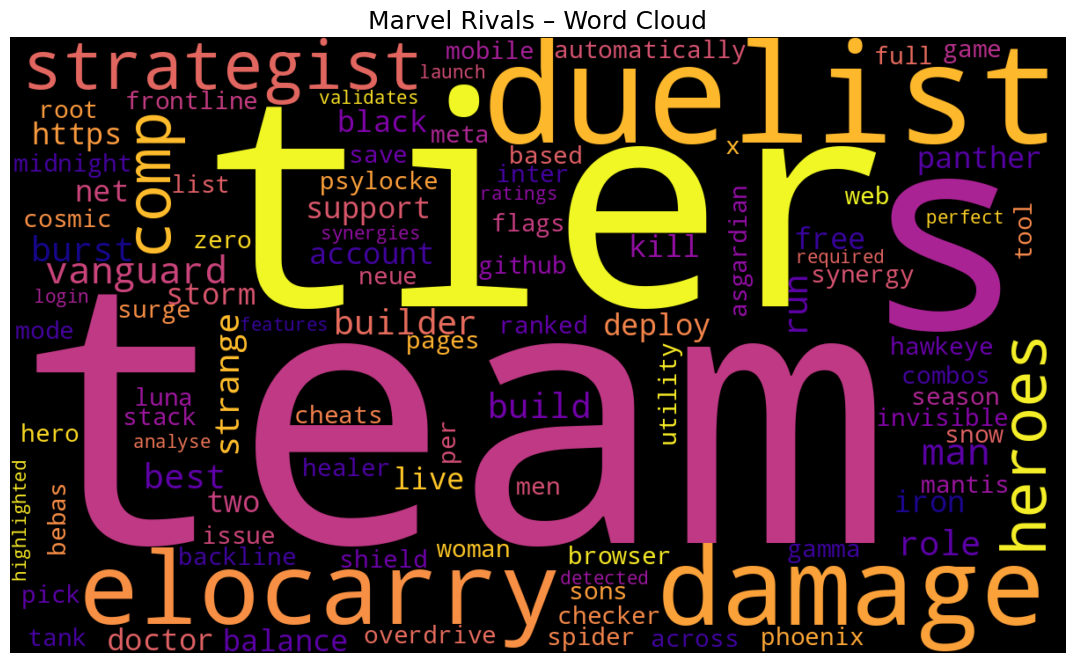

In [9]:
# if WordCloud is not installed i can run this in a notebook cell:
# %pip installs wordcloud matplotlib

import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# reads the text file
with open("marvel_rivals.txt", "r", encoding="utf-8") as file:
    raw_text = file.read()

# removes web links
clean_text = re.sub(r"https?://\\S+", " ", raw_text)

# removes Markdown headings, formatting marks, and punctuation/numbers
clean_text = re.sub(r"[^A-Za-z ]", " ", clean_text)

# converts all words to lowercase
clean_text = clean_text.lower()

# adds common words and game-specific words that are too general
custom_stopwords = set(STOPWORDS)
custom_stopwords.update({
    "the", "and", "for", "with", "from", "this", "that",
    "are", "all", "can", "has", "have", "into", "your",
    "will", "you", "their", "they", "more", "also",
    "marvel", "rivals"
})

# creates the word cloud
wordcloud = WordCloud(
    width=1200,
    height=700,
    background_color="black",
    colormap="plasma",
    stopwords=custom_stopwords,
    max_words=100,
    collocations=False
).generate(clean_text)

# displays the result
plt.figure(figsize=(14, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Marvel Rivals – Word Cloud", fontsize=18)
plt.show()

In this step count which words appear most frequently in the text. I use Counter from the collections librar and then remove stopwords and very short words first. Then i display the 15 most common words. This helps me understand the results of my word cloud better. I can see that word "team" was used most.

In [ ]:
from collections import Counter

# keeps alphabetic words and remove stopwords
clean_words = [
    word for word in clean_text.split()
    if word not in custom_stopwords and len(word) > 2
]

word_counts = Counter(clean_words)

print("15 most common words:")
for word, count in word_counts.most_common(15):
    print(word, "-", count)

15 most common words:
team - 15
tier - 9
duelist - 7
damage - 7
elocarry - 6
heroes - 5
man - 5
builder - 4
comp - 4
role - 4
best - 4
vanguard - 4
strange - 4
strategist - 4
burst - 4


Overall : For this assignment i chose Marvel Rivals as my topic because i am interested in the game.

First, I downloaded a text file from GitHub using Pythons urllib.request library. Then i explored the text by splitting it into words, counting them and printing some parts of it.

For the second task i used the WordCloud library to create a visualisation. Before creating it i cleaned the text by removing punctuation, links and common words. I also added my own stopwords.

The word cloud shows which words appear most frequently in the text. The bigger the word the more often it appears. This helps us understand the main topics discussed in the text without having to read the entire file.